In [8]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import json
from req_functions_from_ApproxSP import *
from tqdm import tqdm
from generate_profiles import *
from euclidean import *
from mallows import *
from impartial import *
from all_stable import *
import pandas as pd
import ast

In [23]:
malechoice = [
    [],             # unused 0 index
    [1, 2, 3, 4],   # man 1's preferences
    [4, 2, 3, 1],   # man 2's preferences
    [2, 1, 3, 4],   # ...
    [1, 2, 4, 3],
]
femalechoice = [
    [],             # unused 0 index
    [1, 4, 3, 2],   # woman 1's preferences
    [3, 2, 1, 4],
    [1, 2, 3, 4],
    [2, 1, 4, 3],
]
n = 5
matchings = find_all_stable(malechoice, femalechoice, n)
print(matchings)

[[1, 4, 2, 3]]


In [24]:
n=5
men_pref = [[], [1, 3, 2, 4],
                    [2, 1, 4, 3],
                    [3, 1, 4, 2],
                    [4, 2, 3, 1]]
women_pref = [[], [4, 3, 1, 2],
                      [3, 4, 1, 2],
                      [2, 1, 4, 3],
                      [1, 3, 2, 4]]
matchings = find_all_stable(men_pref, women_pref, n)
print(matchings)

[[1, 2, 3, 4], [3, 2, 1, 4], [4, 3, 1, 2], [4, 3, 2, 1], [3, 4, 1, 2], [1, 4, 3, 2]]


In [7]:
import numpy as np


def anna_find_all_stable(malechoice, femalechoice, n):
    # Output list with all matchings
    res = []
    # Initialization
    unchanged = [True] * n
    marriage = [0] * n
    malecounter = [0] * n
    # Female choice transformation

    fc = np.zeros((n, n), dtype=int)
    for i in range(0, n):
        for j in range(0, n):
            fc[i][femalechoice[i][j]] = j
        fc[i][0] = n
        malecounter[i] = 0
        marriage[i] = 0

    def get_marriage(marriage):
        malematches = [0] * (n)
        for j in range(0, n):
            malematches[marriage[j] - 1] = j
        return(malematches)

    def print_marriage(marriage):
        malematches = [0] * (n)
        for j in range(0, n):
            malematches[marriage[j] - 1] = j
        print(*malematches)

    def proposal(i, malec, marriage, c):
        if i < 0:
            success = True
        elif (i == 0) or malec[i] == (n - 1) or not (unchanged[i]):  # n not (n+1), as we have n equals 5
            success = False
        else:
            c += 1
            j = malec[i]
            malec[i] = j + 1
            success = refusal(i, malechoice[i][j], malec, marriage, c)
        return success

    def refusal(i, j, malec, marriage, c):
        if fc[j][abs(marriage[j])] > fc[j][i]:
            k = marriage[j]
            marriage[j] = i
            success = proposal(k, malec, marriage, c)
        else:
            success = proposal(i, malec, marriage, c)
        return success

    def breakmariage(malecounter, marriage, i, n, count):
        malecounter_ori = malecounter.copy()
        marriage_ori = marriage.copy()
        marriage[malechoice[i][malecounter[i] - 1]] = -i
        success = proposal(i, malecounter, marriage, count)

        if not (success):
            unchanged[i] = False
            malecounter_ref = malecounter_ori.copy()
            marriage_ref = marriage_ori.copy()
            malecounter = malecounter_ref
            marriage = marriage_ref
            return malecounter, marriage

        #print_marriage(marriage)  # marriage[i] means the woman who is married to i man
        new_marriage = get_marriage(marriage)  # convert into female solution
        res.append(new_marriage)
        # establish the relationships between the original and the obtained stable matching

        for j in range(i, n):
            # if i==2 and j==2:
            #     print("This is it")
            malecounter, marriage = breakmariage(malecounter, marriage, j, n, count)

        for j in range((i + 1), n):
            unchanged[j] = True
        # return malecounter_ori, abs(marriage_ori)
        return malecounter_ori, marriage_ori

    count = 0
    for i in range(0, n):
        proposal(i, malecounter, marriage, count)
    #print_marriage(marriage)

    new_marriage = get_marriage(marriage)  # convert into female solution
    res.append(new_marriage)
    # establish the relationships between the original and the obtained stable matching

    M_optimal_marriage = marriage.copy()
    M_optimal_counter = malecounter.copy()
    for i in range(0, n):
        breakmariage(M_optimal_counter.copy(), M_optimal_marriage.copy(), i, n, count)
    return res


**Euclidean Mallows**

In [24]:
import pandas as pd
import json
from collections import defaultdict

df = pd.read_csv('euclidean_mallows_accomplice.csv')

stable_matchings_count = defaultdict(list)
stable_lst = []

for i in range(len(df)):
    
    mpref = [[]] + json.loads(df.loc[i, 'mpref'])
    wpref = [[]] + json.loads(df.loc[i, 'wpref'])
    
    stable_matchings = find_all_stable(mpref, wpref, len(mpref))
    num_stable_matchings = len(stable_matchings)

    stable_lst.append(num_stable_matchings)
    
    phi1 = df.loc[i, 'phi_m']
    phi2 = df.loc[i, 'phi_w']
    
    stable_matchings_count[(phi1, phi2)].append(num_stable_matchings)

df['number_of_stable_matchings'] = stable_lst

df.to_csv('euclidean_mallows_accomplice.csv', index=False)

averages = {
    (phi1, phi2): sum(counts) / len(counts)
    for (phi1, phi2), counts in stable_matchings_count.items()}

for (phi1, phi2), avg in sorted(averages.items()):
    print(f"phi_m: {phi1}, phi_w: {phi2} -> Average Stable Matchings: {avg:.2f}")


phi_m: 0.0, phi_w: 0.0 -> Average Stable Matchings: 1.00
phi_m: 0.0, phi_w: 0.2 -> Average Stable Matchings: 1.16
phi_m: 0.0, phi_w: 0.4 -> Average Stable Matchings: 1.34
phi_m: 0.0, phi_w: 0.6 -> Average Stable Matchings: 1.67
phi_m: 0.0, phi_w: 0.8 -> Average Stable Matchings: 2.18
phi_m: 0.0, phi_w: 1.0 -> Average Stable Matchings: 9.14
phi_m: 0.2, phi_w: 0.0 -> Average Stable Matchings: 1.13
phi_m: 0.2, phi_w: 0.2 -> Average Stable Matchings: 1.28
phi_m: 0.2, phi_w: 0.4 -> Average Stable Matchings: 1.44
phi_m: 0.2, phi_w: 0.6 -> Average Stable Matchings: 1.87
phi_m: 0.2, phi_w: 0.8 -> Average Stable Matchings: 2.59
phi_m: 0.2, phi_w: 1.0 -> Average Stable Matchings: 8.89
phi_m: 0.4, phi_w: 0.0 -> Average Stable Matchings: 1.36
phi_m: 0.4, phi_w: 0.2 -> Average Stable Matchings: 1.49
phi_m: 0.4, phi_w: 0.4 -> Average Stable Matchings: 1.66
phi_m: 0.4, phi_w: 0.6 -> Average Stable Matchings: 1.82
phi_m: 0.4, phi_w: 0.8 -> Average Stable Matchings: 2.61
phi_m: 0.4, phi_w: 1.0 -> Avera

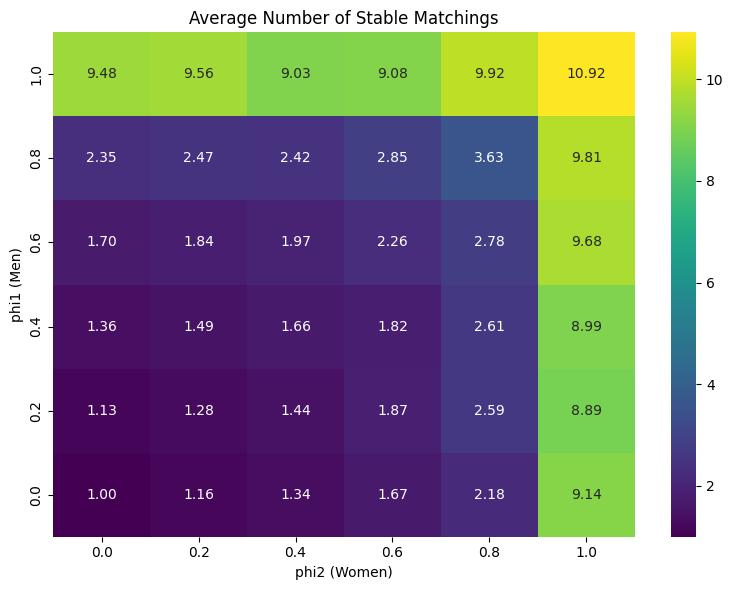

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Define the ordered phi values
phi_list = sorted(set(df['phi_m']).union(df['phi_w']))
phi_index = {phi: i for i, phi in enumerate(phi_list)}
dim = len(phi_list)

# Initialize 2D array to store averages
heatmap_data = np.zeros((dim, dim))

# Fill in the averages
for (phi1, phi2), avg in averages.items():
    i = phi_index[phi1]
    j = phi_index[phi2]
    heatmap_data[i][j] = avg

# Plotting the heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(heatmap_data, annot=True, fmt=".2f", xticklabels=phi_list, yticklabels=phi_list, cmap="viridis")
plt.gca().invert_yaxis()
plt.title("Average Number of Stable Matchings")
plt.xlabel("phi2 (Women)")
plt.ylabel("phi1 (Men)")
plt.tight_layout()
plt.savefig("stability_euclidean_mallows.pdf", format='pdf')
plt.show()


**Reverse Euclidean**

In [18]:
import pandas as pd
import json
from collections import defaultdict

df = pd.read_csv('reverse_euclidean_accomplice.csv')

stable_matchings_count = defaultdict(list)
stable_matchings_count_anna = defaultdict(list)
stable_lst = []
stable_lst_anna = []

for i in range(len(df)):
    
    mpref = json.loads(df.loc[i, 'mpref'])
    wpref = json.loads(df.loc[i, 'wpref'])

    m_pref = [[int(x)-1 for x in sublist] for sublist in mpref]
    w_pref = [[int(x)-1 for x in sublist] for sublist in wpref]
    
    res1 = anna_find_all_stable(m_pref, w_pref, len(m_pref))
    res2 = find_all_stable([[]] + mpref, [[]] + wpref, len(mpref) + 1)
    #print(stable_matchings)
    num_stable_matchings_anna = len(res1)
    num_stable_matchings = len(res2)
    stable_lst.append(num_stable_matchings)
    stable_lst_anna.append(num_stable_matchings_anna)
    
    dimension = df.loc[i, 'dimension']
    proportion = df.loc[i, 'proportion']
    
    stable_matchings_count[(dimension, proportion)].append(num_stable_matchings)
    stable_matchings_count_anna[(dimension, proportion)].append(num_stable_matchings_anna)

df['number_of_stable_matchings'] = stable_lst
df['number_of_stable_matchings_anna'] = stable_lst_anna

df.to_csv('reverse_euclidean_accomplice_test2.csv', index=False)

averages = {
    (dimension, proportion): sum(counts) / len(counts)
    for (dimension, proportion), counts in stable_matchings_count.items()}

#for (dimension, proportion), avg in sorted(averages.items()):
    #print(f"dimension: {dimension}, proportion: {proportion} -> Average Stable Matchings: {avg:.2f}")


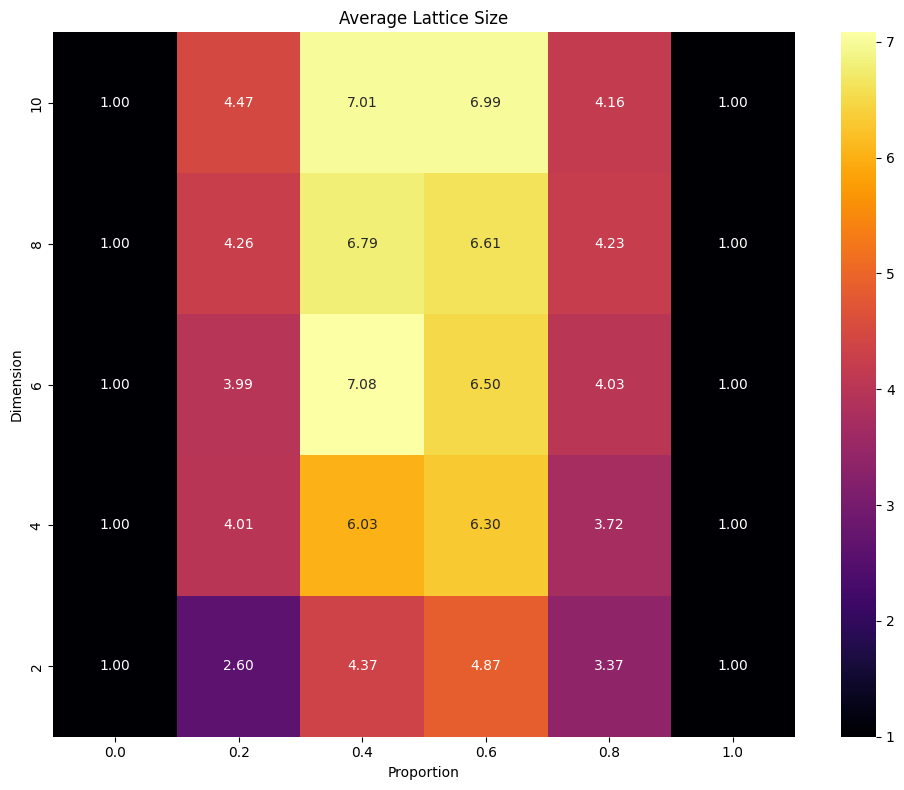

In [20]:

# Load the CSV with stability counts
df = pd.read_csv("reverse_euclidean_accomplice.csv")

# Group by phi_m and phi_w and compute the average number of stable matchings
heatmap_data = (
    df.groupby(["dimension", "proportion"])["number_of_stable_matchings"]
    .mean()
    .reset_index()
)
# Pivot into matrix form for heatmap
heatmap_matrix = heatmap_data.pivot(index="dimension", columns="proportion", values="number_of_stable_matchings")

# Sort the axis values numerically (optional, but often helpful)
heatmap_matrix = heatmap_matrix.sort_index(axis=0).sort_index(axis=1)

# Plot the heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="inferno")
plt.title("Average Lattice Size")
plt.xlabel("Proportion")
plt.ylabel("Dimension")
plt.tight_layout()
plt.gca().invert_yaxis()
plt.show()


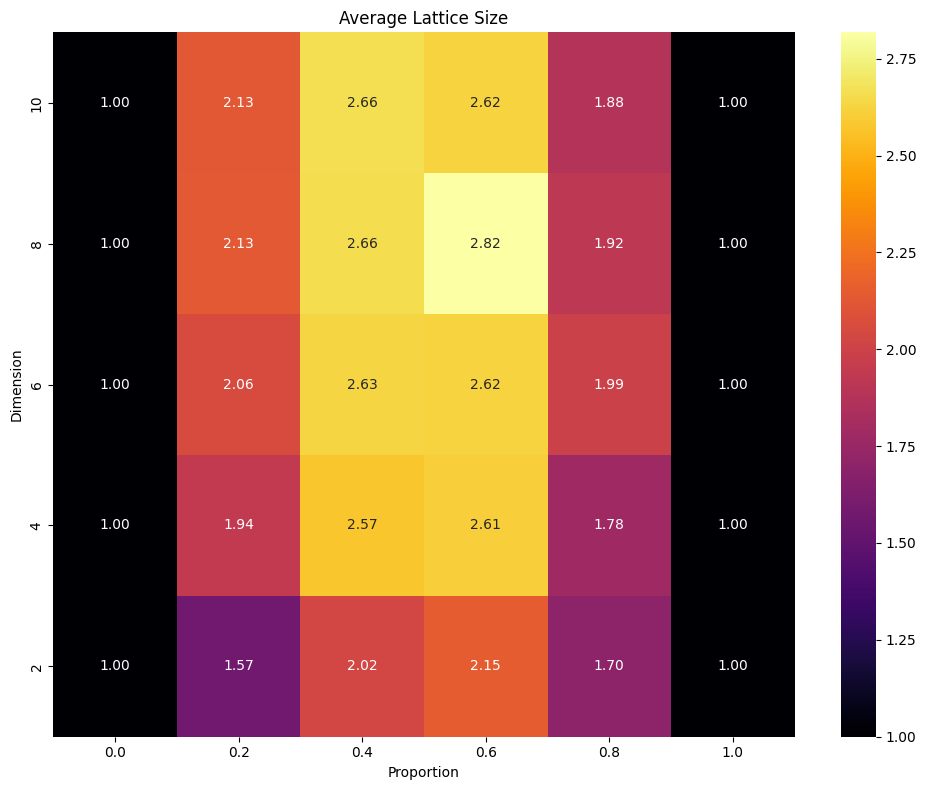

In [17]:

# Load the CSV with stability counts
df = pd.read_csv("reverse_euclidean_accomplice_test2.csv")

# Group by phi_m and phi_w and compute the average number of stable matchings
heatmap_data = (
    df.groupby(["dimension", "proportion"])["number_of_stable_matchings_anna"]
    .mean()
    .reset_index()
)
# Pivot into matrix form for heatmap
heatmap_matrix = heatmap_data.pivot(index="dimension", columns="proportion", values="number_of_stable_matchings_anna")

# Sort the axis values numerically (optional, but often helpful)
heatmap_matrix = heatmap_matrix.sort_index(axis=0).sort_index(axis=1)

# Plot the heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="inferno")
plt.title("Average Lattice Size")
plt.xlabel("Proportion")
plt.ylabel("Dimension")
plt.tight_layout()
plt.gca().invert_yaxis()
plt.show()


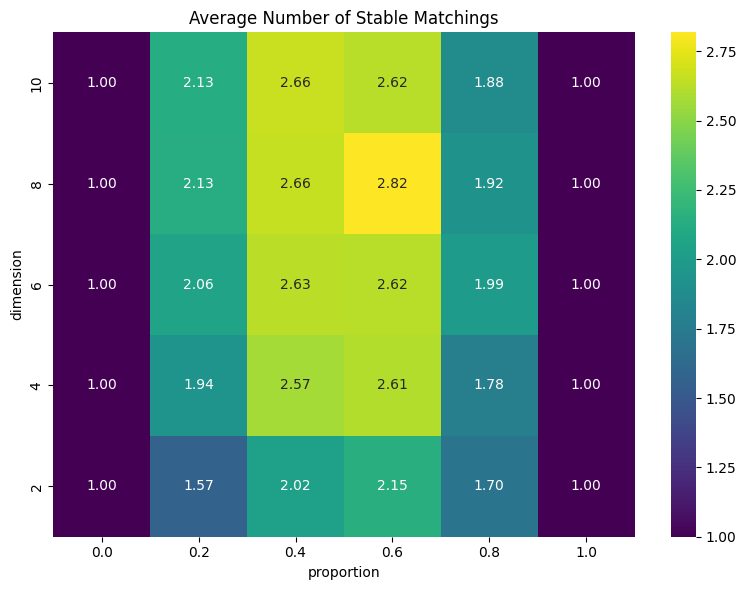

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

dimension = list(sorted(df['dimension'].unique()))
proportion = list(sorted(df['proportion'].unique()))

dimension_index = {d: i for i, d in enumerate(dimension)}
proportion_index = {p: i for i, p in enumerate(proportion)}

heatmap_data = np.zeros((len(dimension), len(proportion)))

for (dim, prop), avg in averages.items():
    i = dimension_index[dim]
    j = proportion_index[prop]
    heatmap_data[i][j] = avg

plt.figure(figsize=(8, 6))
sns.heatmap(heatmap_data, annot=True, fmt=".2f",
            xticklabels=proportion, yticklabels=dimension, cmap="viridis")
plt.gca().invert_yaxis()  
plt.title("Average Number of Stable Matchings")
plt.xlabel("proportion")
plt.ylabel("dimension")
plt.tight_layout()
plt.savefig("stability_reverse_euclidean.pdf", format='pdf')
plt.show()


**Mallows MA**

In [3]:
import pandas as pd
import json
from collections import defaultdict

df = pd.read_csv('mallows_MA_accomplice.csv')

stable_matchings_count = defaultdict(list)
stable_lst = []

for i in range(len(df)):
    
    mpref = [[]] + json.loads(df.loc[i, 'mpref'])
    wpref = [[]] + json.loads(df.loc[i, 'wpref'])
    
    stable_matchings = find_all_stable(mpref, wpref, len(mpref))
    num_stable_matchings = len(stable_matchings)
    stable_lst.append(num_stable_matchings)
    
    phi1 = df.loc[i, 'phi_m']
    phi2 = df.loc[i, 'phi_w']
    
    stable_matchings_count[(phi1, phi2)].append(num_stable_matchings)

df['number_of_stable_matchings'] = stable_lst
df.to_csv('mallows_MA_accomplice.csv', index=False)

#averages = {
    #(phi1, phi2): sum(counts) / len(counts)
    #for (phi1, phi2), counts in stable_matchings_count.items()}

#for (phi1, phi2), avg in sorted(averages.items()):
    #print(f"phi_m: {phi1}, phi_w: {phi2} -> Average Stable Matchings: {avg:.2f}")


**Mallows MD**

In [ ]:
import pandas as pd
import json
from collections import defaultdict

df = pd.read_csv('mallows_MD_accomplice.csv')

stable_matchings_count = defaultdict(list)
stable_lst = []

for i in range(len(df)):
    
    mpref = [[]] + json.loads(df.loc[i, 'mpref'])
    wpref = [[]] + json.loads(df.loc[i, 'wpref'])
    
    stable_matchings = find_all_stable(mpref, wpref, len(mpref))
    num_stable_matchings = len(stable_matchings)
    stable_lst.append(num_stable_matchings)
    
    phi1 = df.loc[i, 'phi_m']
    phi2 = df.loc[i, 'phi_w']
    
    stable_matchings_count[(phi1, phi2)].append(num_stable_matchings)

df['number_of_stable_matchings'] = stable_lst
df.to_csv('mallows_MD_accomplice.csv', index=False)

averages = {
    (phi1, phi2): sum(counts) / len(counts)
    for (phi1, phi2), counts in stable_matchings_count.items()}

for (phi1, phi2), avg in sorted(averages.items()):
    print(f"phi_m: {phi1}, phi_w: {phi2} -> Average Stable Matchings: {avg:.2f}")


phi_m: 0.0, phi_w: 0.0 -> Average Stable Matchings: 30.00
phi_m: 0.0, phi_w: 0.2 -> Average Stable Matchings: 28.57
phi_m: 0.0, phi_w: 0.4 -> Average Stable Matchings: 27.45
phi_m: 0.0, phi_w: 0.6 -> Average Stable Matchings: 25.62
phi_m: 0.0, phi_w: 0.8 -> Average Stable Matchings: 20.55
phi_m: 0.0, phi_w: 1.0 -> Average Stable Matchings: 7.65
phi_m: 0.2, phi_w: 0.0 -> Average Stable Matchings: 28.60
phi_m: 0.2, phi_w: 0.2 -> Average Stable Matchings: 44.57
phi_m: 0.2, phi_w: 0.4 -> Average Stable Matchings: 45.12
phi_m: 0.2, phi_w: 0.6 -> Average Stable Matchings: 36.83
phi_m: 0.2, phi_w: 0.8 -> Average Stable Matchings: 25.07
phi_m: 0.2, phi_w: 1.0 -> Average Stable Matchings: 9.07
phi_m: 0.4, phi_w: 0.0 -> Average Stable Matchings: 27.44
phi_m: 0.4, phi_w: 0.2 -> Average Stable Matchings: 45.39
phi_m: 0.4, phi_w: 0.4 -> Average Stable Matchings: 52.32
phi_m: 0.4, phi_w: 0.6 -> Average Stable Matchings: 45.74
phi_m: 0.4, phi_w: 0.8 -> Average Stable Matchings: 29.50
phi_m: 0.4, phi_

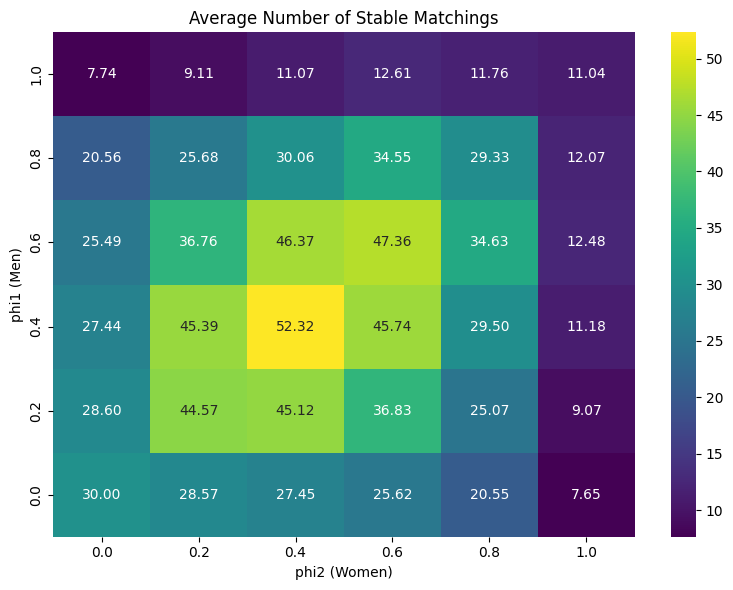

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Define the ordered phi values
phi_list = sorted(set(df['phi_m']).union(df['phi_w']))
phi_index = {phi: i for i, phi in enumerate(phi_list)}
dim = len(phi_list)

# Initialize 2D array to store averages
heatmap_data = np.zeros((dim, dim))

# Fill in the averages
for (phi1, phi2), avg in averages.items():
    i = phi_index[phi1]
    j = phi_index[phi2]
    heatmap_data[i][j] = avg

# Plotting the heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(heatmap_data, annot=True, fmt=".2f", xticklabels=phi_list, yticklabels=phi_list, cmap="viridis")
plt.gca().invert_yaxis()
plt.title("Average Number of Stable Matchings")
plt.xlabel("phi2 (Women)")
plt.ylabel("phi1 (Men)")
plt.tight_layout()
plt.savefig("stability_mallows_MD.pdf", format='pdf')
plt.show()


**Mallows**

In [30]:
import pandas as pd
import json
from collections import defaultdict

df_M = pd.read_csv('mallows_accomplice.csv')

stable_matchings_count = defaultdict(list)
stable_lst = []

for i in range(len(df_M)):
    
    mpref = [[]] + json.loads(df_M.loc[i, 'mpref'])
    wpref = [[]] + json.loads(df_M.loc[i, 'wpref'])
    
    stable_matchings = find_all_stable(mpref, wpref, len(mpref))
    num_stable_matchings = len(stable_matchings)
    stable_lst.append(num_stable_matchings)
    
    phi1 = df_M.loc[i, 'phi_m']
    phi2 = df_M.loc[i, 'phi_w']
    
    stable_matchings_count[(phi1, phi2)].append(num_stable_matchings)

df_M['number_of_stable_matchings'] = stable_lst
df_M.to_csv('mallows_accomplice.csv', index=False)

averages = {
    (phi1, phi2): sum(counts) / len(counts)
    for (phi1, phi2), counts in stable_matchings_count.items()}

for (phi1, phi2), avg in sorted(averages.items()):
    print(f"phi_m: {phi1}, phi_w: {phi2} -> Average Stable Matchings: {avg:.2f}")


phi_m: 0.0, phi_w: 0.0 -> Average Stable Matchings: 1.00
phi_m: 0.0, phi_w: 0.2 -> Average Stable Matchings: 1.00
phi_m: 0.0, phi_w: 0.4 -> Average Stable Matchings: 1.00
phi_m: 0.0, phi_w: 0.6 -> Average Stable Matchings: 1.00
phi_m: 0.0, phi_w: 0.8 -> Average Stable Matchings: 1.00
phi_m: 0.0, phi_w: 1.0 -> Average Stable Matchings: 1.00
phi_m: 0.2, phi_w: 0.0 -> Average Stable Matchings: 1.00
phi_m: 0.2, phi_w: 0.2 -> Average Stable Matchings: 1.66
phi_m: 0.2, phi_w: 0.4 -> Average Stable Matchings: 1.67
phi_m: 0.2, phi_w: 0.6 -> Average Stable Matchings: 1.61
phi_m: 0.2, phi_w: 0.8 -> Average Stable Matchings: 1.30
phi_m: 0.2, phi_w: 1.0 -> Average Stable Matchings: 1.25
phi_m: 0.4, phi_w: 0.0 -> Average Stable Matchings: 1.00
phi_m: 0.4, phi_w: 0.2 -> Average Stable Matchings: 1.73
phi_m: 0.4, phi_w: 0.4 -> Average Stable Matchings: 2.24
phi_m: 0.4, phi_w: 0.6 -> Average Stable Matchings: 2.20
phi_m: 0.4, phi_w: 0.8 -> Average Stable Matchings: 1.88
phi_m: 0.4, phi_w: 1.0 -> Avera

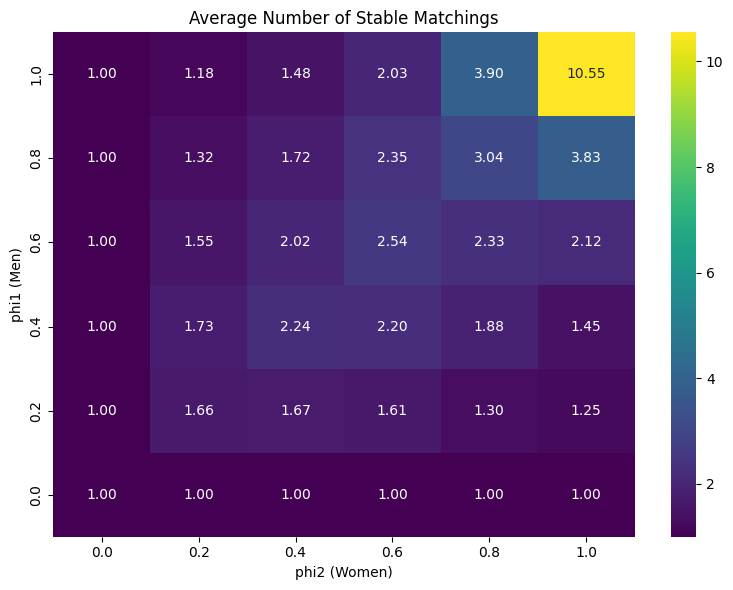

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Define the ordered phi values
phi_list = sorted(set(df_M['phi_m']).union(df_M['phi_w']))
phi_index = {phi: i for i, phi in enumerate(phi_list)}
dim = len(phi_list)

# Initialize 2D array to store averages
heatmap_data = np.zeros((dim, dim))

# Fill in the averages
for (phi1, phi2), avg in averages.items():
    i = phi_index[phi1]
    j = phi_index[phi2]
    heatmap_data[i][j] = avg

# Plotting the heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(heatmap_data, annot=True, fmt=".2f", xticklabels=phi_list, yticklabels=phi_list, cmap="viridis")
plt.gca().invert_yaxis()
plt.title("Average Number of Stable Matchings")
plt.xlabel("phi2 (Women)")
plt.ylabel("phi1 (Men)")
plt.tight_layout()
plt.savefig("stability_mallows.pdf", format='pdf')
plt.show()


**Fame Euclidean**

In [32]:
import pandas as pd
import json
from collections import defaultdict

df = pd.read_csv('fame_euclidean_accomplice.csv')

stable_matchings_count = defaultdict(list)
stable_lst = []

for i in range(len(df)):
    
    mpref = [[]] + json.loads(df.loc[i, 'mpref'])
    wpref = [[]] + json.loads(df.loc[i, 'wpref'])
    
    stable_matchings = find_all_stable(mpref, wpref, len(mpref))
    num_stable_matchings = len(stable_matchings)
    stable_lst.append(num_stable_matchings)
    
    dimension = df.loc[i, 'dimension']
    fame = df.loc[i, 'fame']
    
    stable_matchings_count[(dimension, fame)].append(num_stable_matchings)

df['number_of_stable_matchings'] = stable_lst
df.to_csv('fame_euclidean_accomplice.csv', index=False)

averages = {
    (dimension, fame): sum(counts) / len(counts)
    for (dimension, fame), counts in stable_matchings_count.items()}

for (dimension, proportion), avg in sorted(averages.items()):
    print(f"dimension: {dimension}, fame: {fame} -> Average Stable Matchings: {avg:.2f}")


dimension: 2, fame: 1.0 -> Average Stable Matchings: 1.00
dimension: 2, fame: 1.0 -> Average Stable Matchings: 1.00
dimension: 2, fame: 1.0 -> Average Stable Matchings: 1.00
dimension: 2, fame: 1.0 -> Average Stable Matchings: 1.00
dimension: 2, fame: 1.0 -> Average Stable Matchings: 1.00
dimension: 2, fame: 1.0 -> Average Stable Matchings: 1.00
dimension: 3, fame: 1.0 -> Average Stable Matchings: 1.00
dimension: 3, fame: 1.0 -> Average Stable Matchings: 1.00
dimension: 3, fame: 1.0 -> Average Stable Matchings: 1.00
dimension: 3, fame: 1.0 -> Average Stable Matchings: 1.00
dimension: 3, fame: 1.0 -> Average Stable Matchings: 1.00
dimension: 3, fame: 1.0 -> Average Stable Matchings: 1.00
dimension: 5, fame: 1.0 -> Average Stable Matchings: 1.00
dimension: 5, fame: 1.0 -> Average Stable Matchings: 1.00
dimension: 5, fame: 1.0 -> Average Stable Matchings: 1.00
dimension: 5, fame: 1.0 -> Average Stable Matchings: 1.00
dimension: 5, fame: 1.0 -> Average Stable Matchings: 1.00
dimension: 5, 

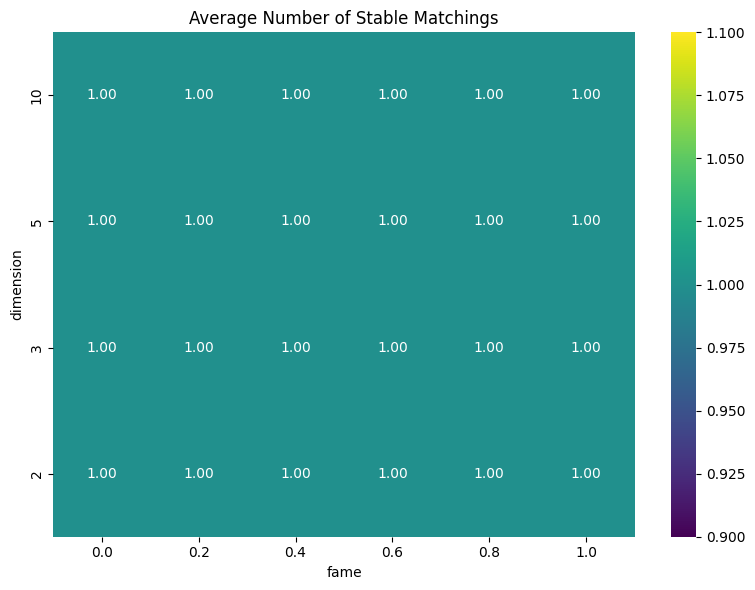

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

dimension = list(sorted(df['dimension'].unique()))
fame = list(sorted(df['fame'].unique()))

dimension_index = {d: i for i, d in enumerate(dimension)}
fame_index = {p: i for i, p in enumerate(fame)}

heatmap_data = np.zeros((len(dimension), len(fame)))

for (dim, fam), avg in averages.items():
    i = dimension_index[dim]
    j = fame_index[fam]
    heatmap_data[i][j] = avg

plt.figure(figsize=(8, 6))
sns.heatmap(heatmap_data, annot=True, fmt=".2f",
            xticklabels=fame, yticklabels=dimension, cmap="viridis")
plt.gca().invert_yaxis()  
plt.title("Average Number of Stable Matchings")
plt.xlabel("fame")
plt.ylabel("dimension")
plt.tight_layout()
plt.savefig("stability_fame_euclidean.pdf", format='pdf')
plt.show()


**Expectations Euclidean**

In [34]:
import pandas as pd
import json
from collections import defaultdict

df = pd.read_csv('expectations_euclidean_accomplice.csv')

stable_matchings_count = defaultdict(list)
stable_lst = []

for i in range(len(df)):
    
    mpref = [[]] + json.loads(df.loc[i, 'mpref'])
    wpref = [[]] + json.loads(df.loc[i, 'wpref'])
    
    stable_matchings = find_all_stable(mpref, wpref, len(mpref))
    num_stable_matchings = len(stable_matchings)
    stable_lst.append(num_stable_matchings)
    
    dimension = df.loc[i, 'dimension']
    std = df.loc[i, 'std']
    
    stable_matchings_count[(dimension, std)].append(num_stable_matchings)

df['number_of_stable_matchings'] = stable_lst
df.to_csv('expectations_euclidean_accomplice.csv', index=False)

averages = {
    (dimension, std): sum(counts) / len(counts)
    for (dimension, std), counts in stable_matchings_count.items()}

for (dimension, standard_deviation), avg in sorted(averages.items()):
    print(f"dimension: {dimension}, standard deviation: {standard_deviation} -> Average Stable Matchings: {avg:.2f}")


dimension: 2, standard deviation: 0.0 -> Average Stable Matchings: 1.00
dimension: 2, standard deviation: 0.2 -> Average Stable Matchings: 3.83
dimension: 2, standard deviation: 0.4 -> Average Stable Matchings: 8.82
dimension: 2, standard deviation: 0.6 -> Average Stable Matchings: 8.64
dimension: 2, standard deviation: 0.8 -> Average Stable Matchings: 8.16
dimension: 2, standard deviation: 1.0 -> Average Stable Matchings: 7.07
dimension: 4, standard deviation: 0.0 -> Average Stable Matchings: 1.00
dimension: 4, standard deviation: 0.2 -> Average Stable Matchings: 1.44
dimension: 4, standard deviation: 0.4 -> Average Stable Matchings: 1.86
dimension: 4, standard deviation: 0.6 -> Average Stable Matchings: 2.13
dimension: 4, standard deviation: 0.8 -> Average Stable Matchings: 2.29
dimension: 4, standard deviation: 1.0 -> Average Stable Matchings: 2.51
dimension: 6, standard deviation: 0.0 -> Average Stable Matchings: 1.00
dimension: 6, standard deviation: 0.2 -> Average Stable Matching

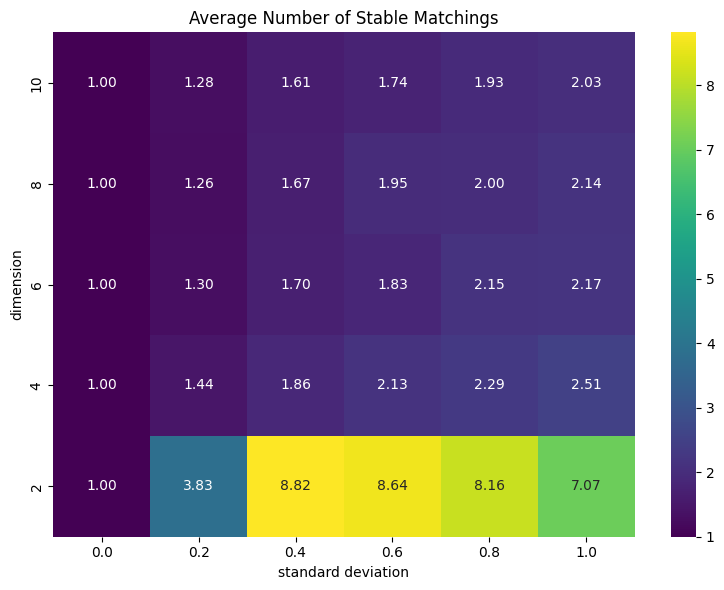

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

dimension = list(sorted(df['dimension'].unique()))
std = list(sorted(df['std'].unique()))

dimension_index = {d: i for i, d in enumerate(dimension)}
std_index = {p: i for i, p in enumerate(std)}

heatmap_data = np.zeros((len(dimension), len(std)))

for (dim, stan), avg in averages.items():
    i = dimension_index[dim]
    j = std_index[stan]
    heatmap_data[i][j] = avg

plt.figure(figsize=(8, 6))
sns.heatmap(heatmap_data, annot=True, fmt=".2f",
            xticklabels=std, yticklabels=dimension, cmap="viridis")
plt.gca().invert_yaxis()  
plt.title("Average Number of Stable Matchings")
plt.xlabel("standard deviation")
plt.ylabel("dimension")
plt.tight_layout()
plt.savefig("stability_expectations_euclidean.pdf", format='pdf')
plt.show()


**Attributes**

In [36]:
import pandas as pd
import json
from collections import defaultdict

df = pd.read_csv('attributes.csv')

stable_matchings_count = defaultdict(list)
stable_lst = []

for i in range(len(df)):
    
    mpref = [[]] + json.loads(df.loc[i, 'mpref'])
    wpref = [[]] + json.loads(df.loc[i, 'wpref'])
    
    stable_matchings = find_all_stable(mpref, wpref, len(mpref))
    num_stable_matchings = len(stable_matchings)
    stable_lst.append(num_stable_matchings)
    
    dimension = df.loc[i, 'dimension']
    
    stable_matchings_count[(dimension)].append(num_stable_matchings)

df['number_of_stable_matchings'] = stable_lst
df.to_csv('attributes.csv', index=False)

averages = {
    (dimension): sum(counts) / len(counts)
    for (dimension), counts in stable_matchings_count.items()}

for (dimension), avg in sorted(averages.items()):
    print(f"dimension: {dimension}, -> Average Stable Matchings: {avg:.2f}")


dimension: 2, -> Average Stable Matchings: 1.51
dimension: 4, -> Average Stable Matchings: 2.04
dimension: 6, -> Average Stable Matchings: 2.19
dimension: 8, -> Average Stable Matchings: 2.15
dimension: 10, -> Average Stable Matchings: 2.17
dimension: 12, -> Average Stable Matchings: 2.36
dimension: 14, -> Average Stable Matchings: 2.29
dimension: 16, -> Average Stable Matchings: 2.26
dimension: 18, -> Average Stable Matchings: 2.32
dimension: 20, -> Average Stable Matchings: 2.34


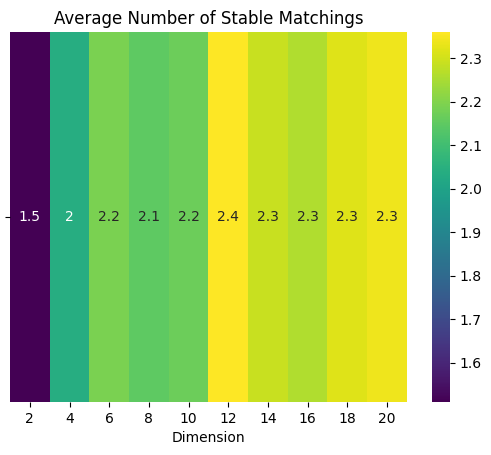

In [40]:
import numpy as np

values = [1.51, 2.04, 2.19, 2.15, 2.17, 2.36, 2.29, 2.26, 2.32, 2.34]
d_list = [2, 4, 6, 8, 10, 12, 14, 16, 18, 20]


heatmap_data = np.array([values])

sns.heatmap(heatmap_data, annot=True, xticklabels=d_list, yticklabels=[""], cmap="viridis")
plt.xlabel('Dimension')
plt.title('Average Number of Stable Matchings')
plt.savefig("stability_attributes.pdf", format='pdf')
plt.show()
